In [16]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [17]:
df = pd.read_parquet("hf://datasets/afzalmengal/nfl-4th-downs-dataset/data/train-00000-of-00001.parquet")

df['play_type'] = df['play_type'].replace({'pass': 'go', 'run': 'go', 'qb_kneel': 'no_play'})


In [18]:
train_seasons = list(range(1999,2021))
val_seasons =  [2023, 2024, 2025]
test_seasons = [2020, 2021, 2022]



train_df = df[df['season'].isin(train_seasons)]
val_df = df[df['season'].isin(val_seasons)]

train_df['game_fraction_remaining'] = train_df['game_seconds_remaining'] / 3600.0
val_df['game_fraction_remaining'] = val_df['game_seconds_remaining'] / 3600.0


In [19]:
features_list = ['score_differential', 'ydstogo', 'yardline_100', 'game_fraction_remaining']

subset_df_train = train_df[[
    'wpa',
    'play_type'] + features_list ].copy().dropna()


# filter out 'no_play' 
subset_df_train = subset_df_train[subset_df_train['play_type'].isin(['go', 'field_goal', 'punt'])].copy()
val_df = val_df[val_df['play_type'].isin(['go', 'field_goal', 'punt'])].copy()


In [20]:
def engineer_features(df):
    df_new = df.copy()
    
    df_new['yardline_centered'] = df_new['yardline_100'] - 50
    df_new['yardline_centered_sq'] = (df_new['yardline_centered'] ** 2) / 1000.0
    
    df_new['urgency'] = df_new['score_differential'] * df_new['game_fraction_remaining']
    
    return df_new

subset_df_train = engineer_features(subset_df_train)

features = [
    'score_differential', 
    'ydstogo', 
    'yardline_centered', 
    'yardline_centered_sq', 
    'game_fraction_remaining', 
    'urgency'
]



train_go = subset_df_train[subset_df_train['play_type'] == 'go']
train_fg = subset_df_train[subset_df_train['play_type'] == 'field_goal']
train_punt = subset_df_train[subset_df_train['play_type'] == 'punt']

# Fit Go model
X_train_go = sm.add_constant(train_go[features].astype(float))
y_train_go = train_go['wpa']
model_go = sm.OLS(y_train_go, X_train_go).fit()

# Fit FG model
X_train_fg = sm.add_constant(train_fg[features].astype(float))
y_train_fg = train_fg['wpa']
model_fg = sm.OLS(y_train_fg, X_train_fg).fit()

# Fit Punt model
X_train_punt = sm.add_constant(train_punt[features].astype(float))
y_train_punt = train_punt['wpa']
model_punt = sm.OLS(y_train_punt, X_train_punt).fit()


In [21]:
print('############################## GO ####################################################')
print(model_go.summary())
print('############################## FIELD GOAL ####################################################')
print(model_fg.summary())
print('############################## PUNT ####################################################')
print(model_punt.summary())

############################## GO ####################################################
                            OLS Regression Results                            
Dep. Variable:                    wpa   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                     25.54
Date:                Tue, 21 Jul 2026   Prob (F-statistic):           2.62e-30
Time:                        13:19:29   Log-Likelihood:                 11281.
No. Observations:               11338   AIC:                        -2.255e+04
Df Residuals:                   11331   BIC:                        -2.250e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

In [22]:
y_test_actual = []
y_test_pred = []



# Loop through the test set and predict using the model matching the actual play chosen
for idx, row in val_df.iterrows():
   
    # Feature Engineering 
    yardline_centered = row['yardline_100'] - 50
    yardline_centered_sq = (yardline_centered ** 2) / 1000.0
    urgency = row['score_differential'] * row['game_fraction_remaining']
    
    input_vector = [1.0, row['score_differential'], row['ydstogo'],yardline_centered, yardline_centered_sq, row['game_fraction_remaining'], urgency]
    actual_wpa = row['wpa']
    play = row['play_type']
    
    if play == 'go':
        pred_wpa = model_go.predict([input_vector])[0]
    elif play == 'field_goal':
        pred_wpa = model_fg.predict([input_vector])[0]
    elif play == 'punt':
        pred_wpa = model_punt.predict([input_vector])[0]
    
    y_test_actual.append(actual_wpa)
    y_test_pred.append(pred_wpa)

y_test_actual = np.array(y_test_actual)
y_test_pred = np.array(y_test_pred)
residuals_test = y_test_actual - y_test_pred

# Metrics
mse_test = np.mean(residuals_test**2)
rmse_test = np.sqrt(mse_test)
mae_test = np.mean(np.abs(residuals_test))


ss_res = np.sum(residuals_test**2)
ss_tot = np.sum((y_test_actual - np.mean(y_test_actual))**2)
r2_test = 1 - (ss_res / ss_tot)

print(f"Test Mean Squared Error (MSE):       {mse_test:.8f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse_test:.8f}")
print(f"Test Mean Absolute Error (MAE):     {mae_test:.8f}")
print(f"Test R-squared:                      {r2_test:.6f} ({r2_test*100:.4f}%)")

Test Mean Squared Error (MSE):       0.00378209
Test Root Mean Squared Error (RMSE): 0.06149870
Test Mean Absolute Error (MAE):     0.03573513
Test R-squared:                      0.022644 (2.2644%)


OVERALL ACCURACY: 42.80%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Go for it       0.26      0.83      0.40      2580
  Field Goal       0.64      0.49      0.56      3124
        Punt       0.94      0.24      0.38      6513

    accuracy                           0.43     12217
   macro avg       0.61      0.52      0.44     12217
weighted avg       0.72      0.43      0.43     12217



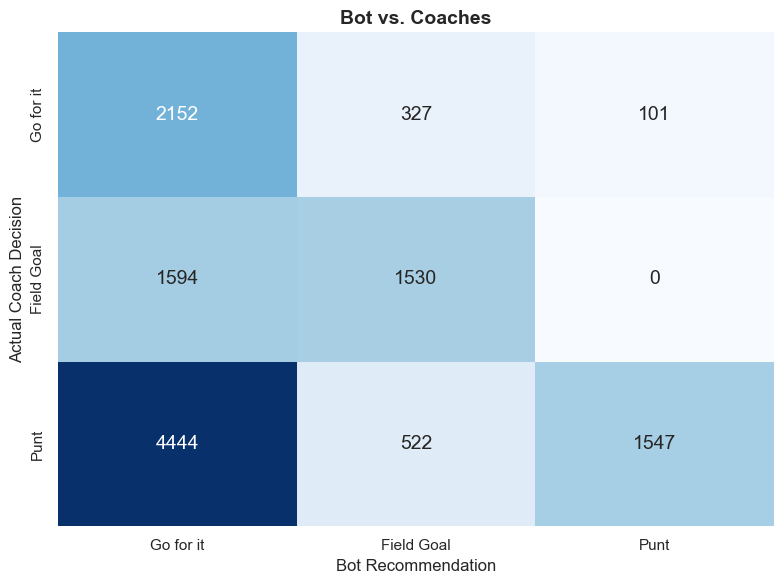

In [23]:
# BOT SIMULATION


def get_threemodel_recommendation(score_diff, yds_to_go, yardline_100, seconds_remaining, quiet=True):

    game_frac = seconds_remaining / 3600.0
    yardline_centered = yardline_100 - 50
    yardline_centered_sq = (yardline_centered ** 2) / 1000.0
    urgency = score_diff * game_frac
    
    input_vector = [1.0, score_diff, yds_to_go, yardline_centered, yardline_centered_sq, game_frac, urgency]
    
    pred_go = model_go.predict([input_vector])[0]
    pred_fg = model_fg.predict([input_vector])[0]
    pred_punt = model_punt.predict([input_vector])[0]
    
    results = {
        "Punt": pred_punt,
        "Field Goal": pred_fg,
        "Go for it": pred_go
    }
    best_action = max(results, key=results.get)
    return best_action, results


y_pred = []


for index, row in val_df.iterrows():
    score_diff = row['score_differential']
    yds_to_go = row['ydstogo']
    yardline_100 = row['yardline_100']
    seconds_remaining = row['game_seconds_remaining']
    
    
    best_action, results_dict = get_threemodel_recommendation(
        score_diff=score_diff,
        yds_to_go=yds_to_go,
        yardline_100=yardline_100,
        seconds_remaining=seconds_remaining,
        quiet=True
    )
    
    y_pred.append(best_action)

# Map for aesthetics

actual_map = {
    'go': 'Go for it',
    'field_goal': 'Field Goal',
    'punt': 'Punt'
}
y_true = val_df['play_type'].map(actual_map).fillna('Unknown').tolist()
action_names = ['Go for it', 'Field Goal', 'Punt']



overall_acc = accuracy_score(y_true, y_pred)

print(f"OVERALL ACCURACY: {overall_acc * 100:.2f}%\n")
print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_true, y_pred, labels=action_names, zero_division=0))


# CONFUSION MATRIX

cm = confusion_matrix(y_true, y_pred, labels=action_names)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=action_names, yticklabels=action_names, 
            cbar=False, annot_kws={"size": 14})

plt.title("Bot vs. Coaches", fontsize=14, fontweight='bold')
plt.ylabel('Actual Coach Decision', fontsize=12)
plt.xlabel('Bot Recommendation', fontsize=12)
plt.tight_layout()
plt.show()

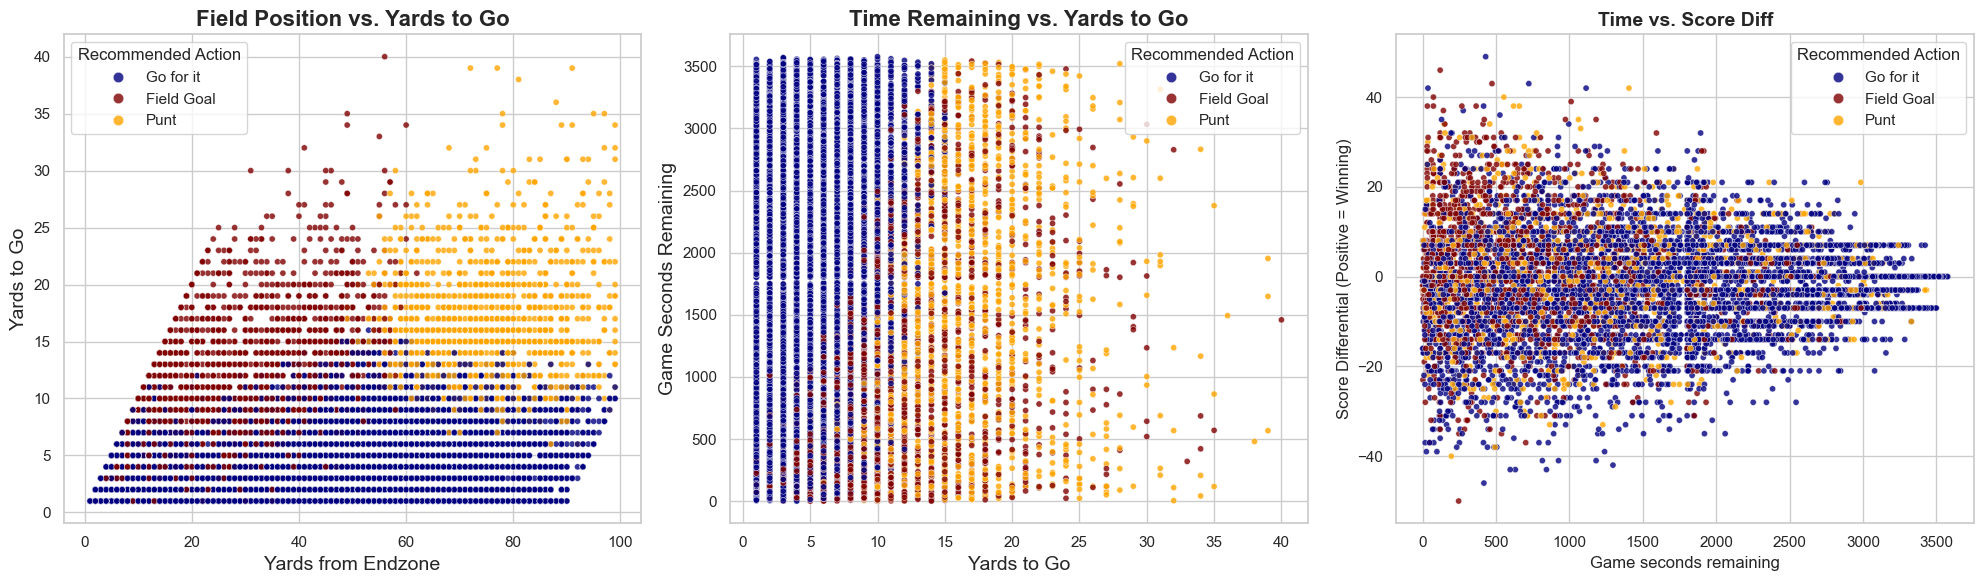

In [24]:
intercepts = np.ones(len(val_df))


plot_df = val_df.copy()
plot_df['OLS_Decision'] = y_pred

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.set_theme(style="whitegrid")

custom_palette = {"Go for it": "navy", "Field Goal": "maroon", "Punt": "orange"}

locked_order = ["Go for it", "Field Goal", "Punt"]

# Yards to Go vs. Field Position
sns.scatterplot(
    data=plot_df, x='yardline_100', y='ydstogo', hue='OLS_Decision', 
    palette=custom_palette, hue_order=locked_order, alpha=0.8, s=20, ax=axes[0]
)
axes[0].set_title("Field Position vs. Yards to Go", fontsize=16, fontweight='bold')
axes[0].set_xlabel("Yards from Endzone", fontsize=14)
axes[0].set_ylabel("Yards to Go", fontsize=14)
leg = axes[0].legend(title="Recommended Action", title_fontsize=12, fontsize=11)

for handle in leg.legend_handles:
    handle.set_markersize(7.5)


# Yards to Go vs. Seconds Remaining
sns.scatterplot(
    data=plot_df,  x='ydstogo',y='game_seconds_remaining', hue='OLS_Decision', 
    palette=custom_palette, hue_order=locked_order, alpha=0.8, s=20, ax=axes[1]
)
axes[1].set_title("Time Remaining vs. Yards to Go", fontsize=16, fontweight='bold')
axes[1].set_ylabel("Game Seconds Remaining", fontsize=14)
axes[1].set_xlabel("Yards to Go", fontsize=14)

leg = axes[1].legend(title="Recommended Action", title_fontsize=12, fontsize=11)

for handle in leg.legend_handles:
    handle.set_markersize(7.5)

#  Score Differential vs. Field Position
sns.scatterplot(
    data=plot_df, x='game_seconds_remaining', y='score_differential', hue='OLS_Decision', 
    palette=custom_palette, hue_order=locked_order, alpha=0.8, s=20, ax=axes[2]
)
axes[2].set_title("Time vs. Score Diff", fontsize=14, fontweight='bold')
axes[2].set_xlabel("Game seconds remaining")
axes[2].set_ylabel("Score Differential (Positive = Winning)")
leg = axes[2].legend(title="Recommended Action", title_fontsize=12, fontsize=11)


for handle in leg.legend_handles:
    handle.set_markersize(7.5)


plt.tight_layout()

plt.show()